# Logger — Analyse des données
Visualisation des températures et états depuis la base MariaDB `logger`.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import mysql.connector

plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['font.size'] = 10

DB = dict(host='192.168.1.165', user='jo_pc', password='mablonde', database='logger')

def get_data(hours=24):
    con = mysql.connector.connect(**DB)
    df = pd.read_sql(
        f"SELECT * FROM tlog WHERE time_stamp >= NOW() - INTERVAL {hours} HOUR ORDER BY time_stamp",
        con, parse_dates=['time_stamp']
    )
    con.close()
    return df

# Noms des capteurs
SENSORS = {
    't0':  'from pac',
    't1':  'to pac',
    't2':  'from accu',
    't3':  'on bypass',
    't4':  'to home',
    't5':  'from home rez',
    't6':  'from home 1er',
    't7':  'from home',
    't8':  'from home after bypass',
    't9':  'to boiler',
    't10': 'boiler',
    't11': 'from boiler',
    't12': 'salon',
    't13': 'bureau',
    't14': 'exterieur',
    't15': 'reduit',
    't16': 'congelateur',
}

STATES = {
    's10': 'pump boiler',
    's11': 'pump home',
    's20': 'pac',
    's21': 's21',
    's30': 's30',
    's31': 's31',
}

print('Librairies OK')

Librairies OK


In [6]:
# Charger les données — modifier 'hours' selon besoin
HOURS = 168

df = get_data(HOURS)
# Remplacer -333 (erreur capteur) par NaN
df.replace(-333, float('nan'), inplace=True)

print(f"{len(df)} mesures sur les {HOURS} dernières heures")
print(f"De {df['time_stamp'].min()} à {df['time_stamp'].max()}")
df.tail(3)

C:\Users\jmetr\AppData\Local\Temp\ipykernel_3748\2223969515.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(


4540 mesures sur les 168 dernières heures
De 2026-11-18 11:07:21 à 2026-11-25 11:04:29


,t0,t1,t2,t3,t4,t5,t6,t7,t8,t9,...,t19,t20,s10,s11,s20,s21,s30,s31,id,time_stamp
4537,35.50,29.81,33.12,31.87,33.12,29.93,26.87,29.93,30.25,28.81,...,NaN,NaN,0,1,1,0,-1,-1,1658043,2026-11-25 11:00:02
4538,35.43,29.81,33.43,32.18,33.50,30.00,27.00,30.00,30.31,28.81,...,NaN,NaN,0,1,1,0,-1,-1,1658044,2026-11-25 11:02:16
4539,35.50,30.00,33.75,32.43,33.81,30.06,27.06,30.12,30.43,28.75,...,NaN,NaN,0,1,1,0,-1,-1,1658045,2026-11-25 11:04:29


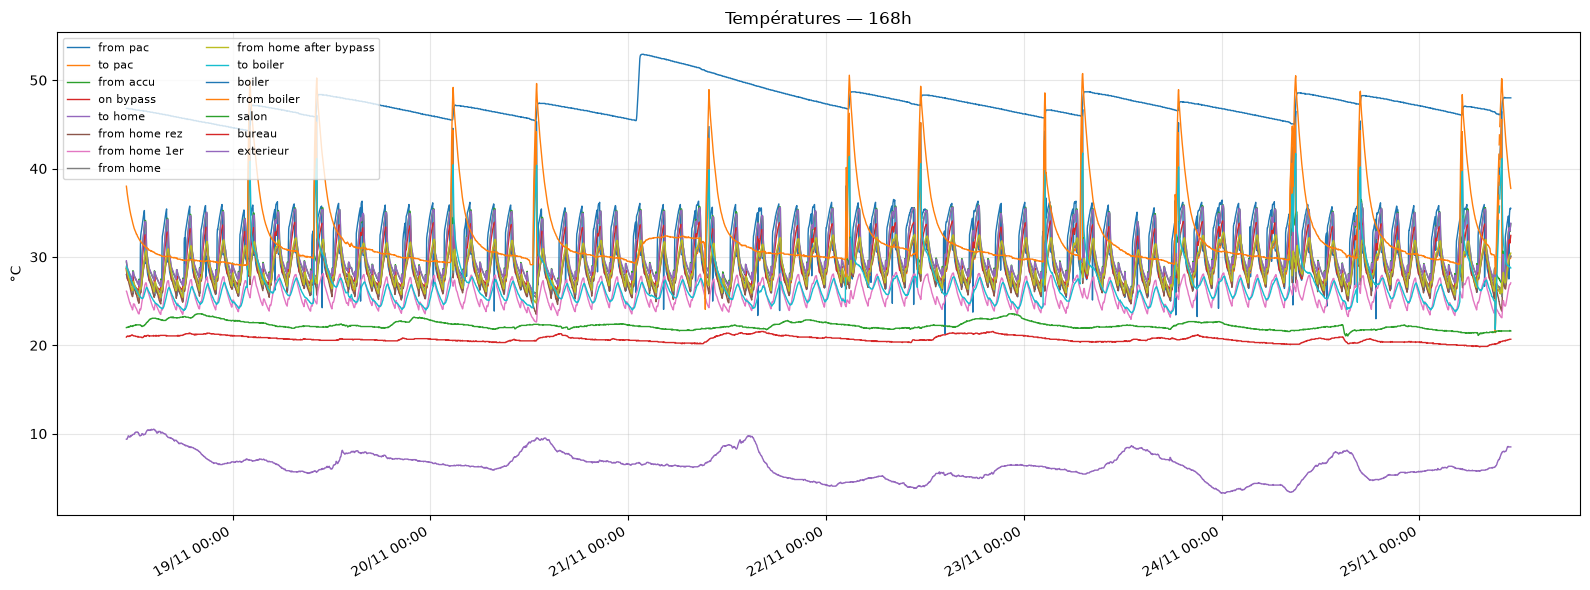

In [7]:
# --- Toutes les températures ---
fig, ax = plt.subplots()

for col, label in SENSORS.items():
    series = df[col].dropna()
    if series.notna().any():
        ax.plot(df['time_stamp'], df[col], label=label, linewidth=1)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M'))
fig.autofmt_xdate()
ax.set_title(f'Températures — {HOURS}h')
ax.set_ylabel('°C')
ax.legend(loc='upper left', fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

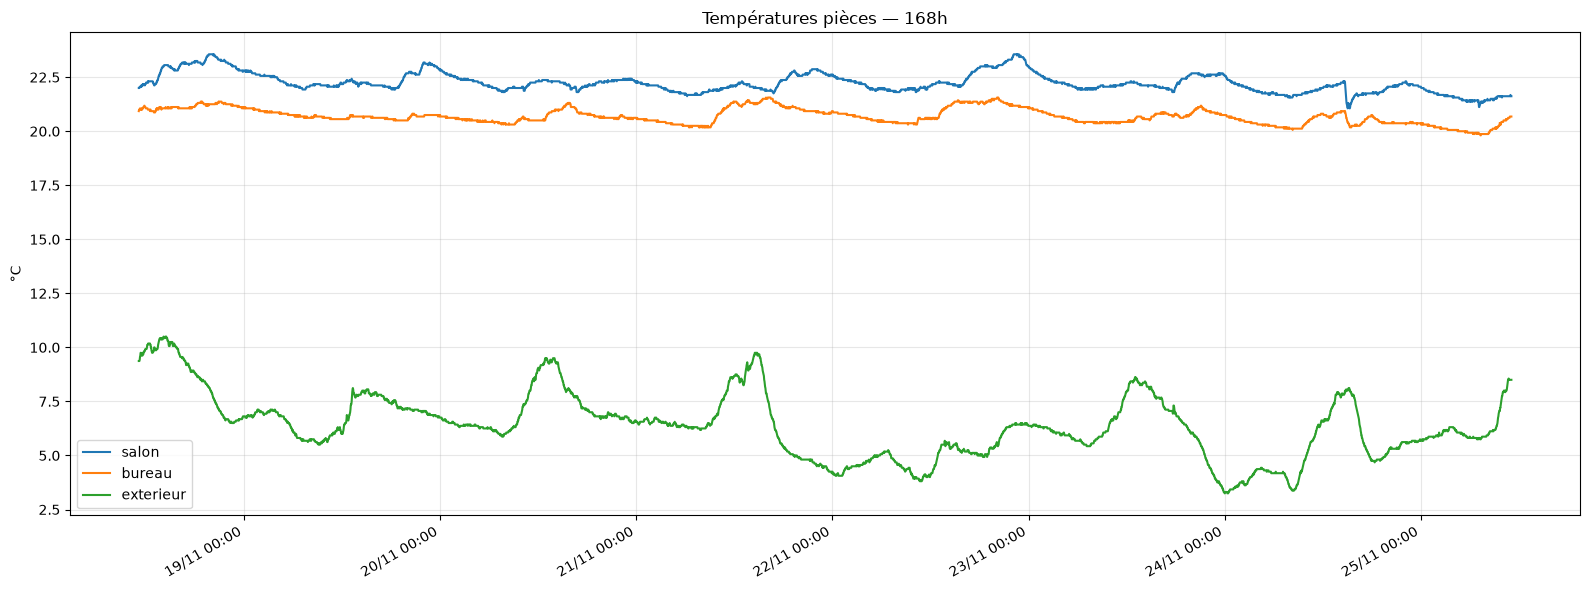

In [8]:
# --- Températures pièces (salon, bureau, extérieur) ---
fig, ax = plt.subplots()

pieces = {'t12': 'salon', 't13': 'bureau', 't14': 'exterieur'}
for col, label in pieces.items():
    ax.plot(df['time_stamp'], df[col], label=label, linewidth=1.5)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M'))
fig.autofmt_xdate()
ax.set_title(f'Températures pièces — {HOURS}h')
ax.set_ylabel('°C')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

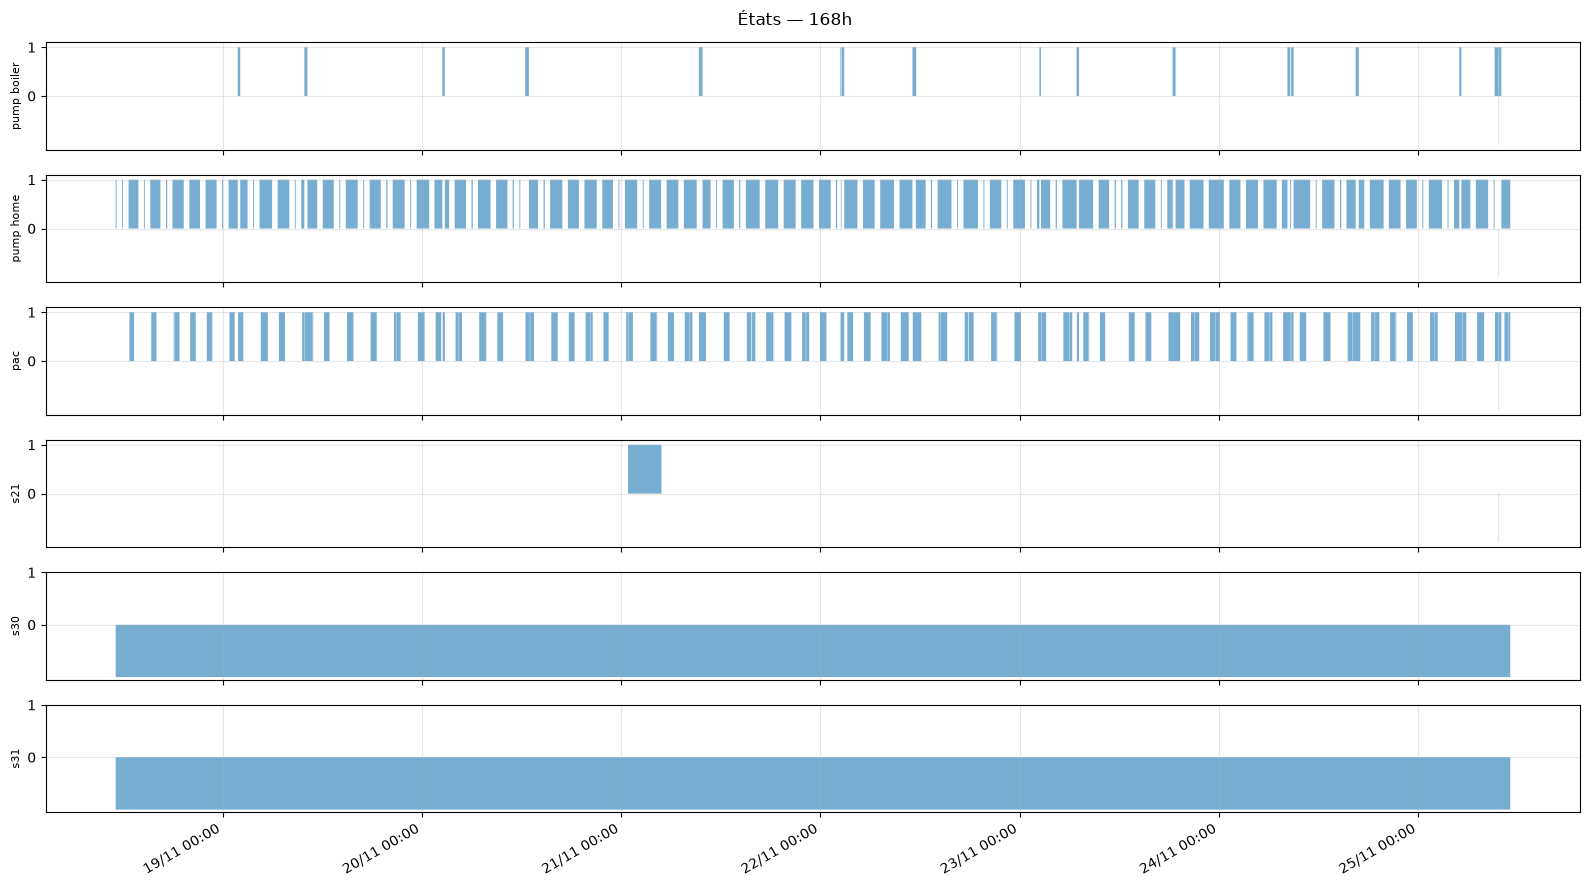

In [9]:
# --- États des pompes / PAC ---
fig, axes = plt.subplots(len(STATES), 1, figsize=(16, len(STATES) * 1.5), sharex=True)

for ax, (col, label) in zip(axes, STATES.items()):
    ax.fill_between(df['time_stamp'], df[col], step='post', alpha=0.6)
    ax.set_ylabel(label, fontsize=8)
    ax.set_yticks([0, 1])
    ax.grid(alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M'))
fig.autofmt_xdate()
fig.suptitle(f'États — {HOURS}h')
plt.tight_layout()
plt.show()